# The BB84 Quantum Cryptography Algorithm

This notebook explores the BB84 QKD (Quantum Key Distribution) protocol, which enables two parties (Alice and Bob) to generate a shared key with information-theoretic security. This approach is significantly more robust than classical methods, which depend on computationally intensive or mathematically complex problems to ensure security against classical computers.

## Quantum Key Distribution using Qiskit

Imagine two people, Alice wants to communicate a secret message to Bob over an insecure medium such as the Internet. Since the Internet is publicly available for anyone to intercept, a special encryption scheme must be developed such that Bob can only access Alice's message with a special "key". We will focus on the BB84 algorithm, which is a symmetric key distribution algorithm enabling Alice to securely communicate her message to Bob.

We will import the required libraries

In [1]:
!pip install qiskit[visualization] qiskit-ibm-runtime qiskit-aer qiskit_ibm_runtime pylatexenc prettytable

In [2]:
import numpy as np
from qiskit import QuantumCircuit
from qiskit.quantum_info import Pauli, SparsePauliOp, Statevector
from qiskit.visualization import plot_histogram, plot_bloch_multivector
from qiskit_aer import AerSimulator
from qiskit.circuit import Parameter, ParameterVector
import qiskit.qasm3
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime import SamplerV2 as Sampler



### Encryption using Quantum Cryptography

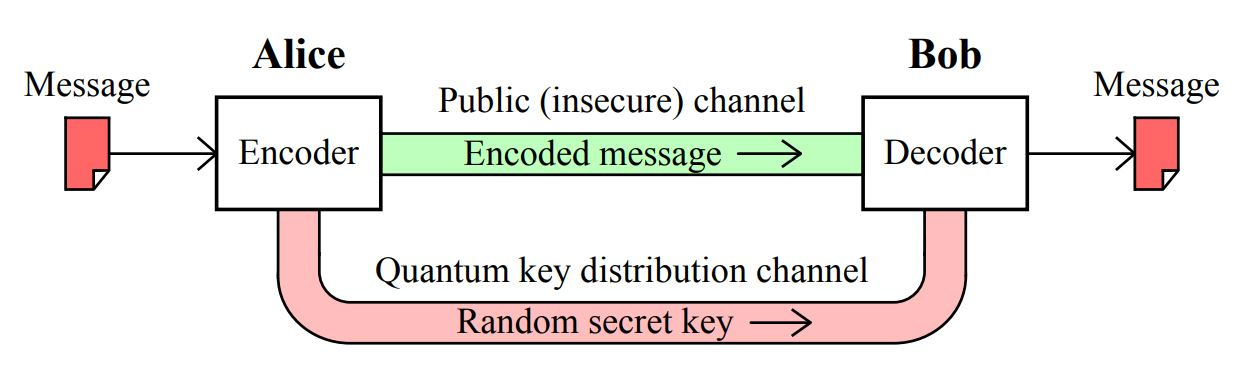

(credit:norwegiancreations.com)

But what are the quantum and classical channels? A classical channel could be a communication wire like a telephone line where electrical signals represent bits or encoded information we send. A quantum communication channel can be a fiber optic cable( as quantum cryptography is implemented using polarization scrambling) through which we can send individual photons (particles of light). The polarization states are used to represent qubits.

### Step 1: Generate Binary Strings

Alice will generate two strings(consisting of 0s and 1s). One string will encode the basis for each qubit and the other string will encode its state.

0 in the hadamard basis will be represented as state $|+\rangle$ and 1 in the hadamard basis is represented as state $|-\rangle$. The hadamard basis can be seen as the result of applying a hadamard gate on the computational basis $|0\rangle$ or $|1\rangle$. The computational basis will be represented by 0 and hadamard basis by 1. Let us suppose that Alice wants to generate a 32 bit string. The number of qubits needed is 32. We will generate two random strings that represent Alice's state and the basis that Alice uses for encoding the state( the information about which basis Alice uses for encoding the state is very important for Bob to decrypt the message using the key)

In [3]:
num_qubits = 32

alice_basis = np.random.randint(2, size=num_qubits)
alice_state = np.random.randint(2, size=num_qubits)
bob_basis = np.random.randint(2, size=num_qubits)


print(f"Alice's State:\t {np.array2string(alice_state)}")
print(f"Alice's Bases:\t {np.array2string(alice_basis)}")
print(f"Bob's Bases:\t {np.array2string(bob_basis)}")




Alice's State:	 [1 0 1 1 1 0 1 1 1 1 1 0 0 1 0 0 1 0 0 1 0 0 0 1 0 0 0 0 1 1 0 1]
Alice's Bases:	 [1 1 0 0 0 0 0 0 1 0 1 1 1 0 1 0 0 1 0 1 0 0 0 1 1 0 0 1 0 1 1 0]
Bob's Bases:	 [0 1 1 0 1 1 1 0 1 1 1 1 0 0 0 1 1 1 0 0 1 0 1 1 1 1 1 1 0 1 1 0]


Now, when Alice's State is 1 and her basis is 0, this means that she is using the computational basis to encode the state 1. However, if Alice's state is 1 and her basis is 1, that means she is using the hadamard gate to encode the state 1 which will result in $|-\rangle$

### Step 2: Creating the circuit using BB84 protocol

We will use this algorithm to construct the circuit

1. Whenever Alice wants to encode 1 in a qubit, she applies an X gate to the qubit. To encode 0, no action is needed as the qubits in qiskit are by default initialized to state 0 and applying an X gate is the equivalent of applying NOT.


2. Wherever she wants to encode it in the Hadamard basis, she applies an hadamard gate. No action is necessary to encode a qubit in the computational basis as the default basis in qiskit is the computational basis


3. She then *sends* the qubits to Bob

4. Bob measures the qubits according to his binary string. To measure a qubit in the Hadamard basis, he applies an hadamard gate to the corresponding qubit and then performs a measurement on the computational basis.

In [4]:
def bb84_circuit(state, basis, measurement_basis):

    #state: array of 0s and 1s denoting the state to be encoded
    #basis: array of 0s and 1s denoting the basis to be used for encoding
                #0 -> Computational Basis
                #1 -> Hadamard Basis
    #meas_basis: array of 0s and 1s denoting the basis to be used for measurement
                #0 -> Computational Basis
                #1 -> Hadamard Basis

    num_qubits = len(state)

    bb84_circuit = QuantumCircuit(num_qubits)

    # Sender prepares qubits
    #for i in range(len(basis)):
      #Include your code here
    for i in range(len(basis)):
        # If Alice wants to send a 1, flip from default |0> to |1>
        if state[i] == 1:
            bb84_circuit.x(i)
        # If Alice chooses Hadamard basis (1), apply H gate to get |+> or |->
        if basis[i] == 1:
            bb84_circuit.h(i)

    bb84_circuit.barrier()

    # Measuring action performed by Bob
    #for i in range(len(measurement_basis)):
      #Include your code here
    for i in range(len(measurement_basis)):
        # If Bob measures in Hadamard basis (1), rotate back before computational measurement
        if measurement_basis[i] == 1:
            bb84_circuit.h(i)

    bb84_circuit.barrier()

    #Measure all qubits
    #Include your code here
    bb84_circuit.measure_all()

    return bb84_circuit

Execute the function and show the circuit:

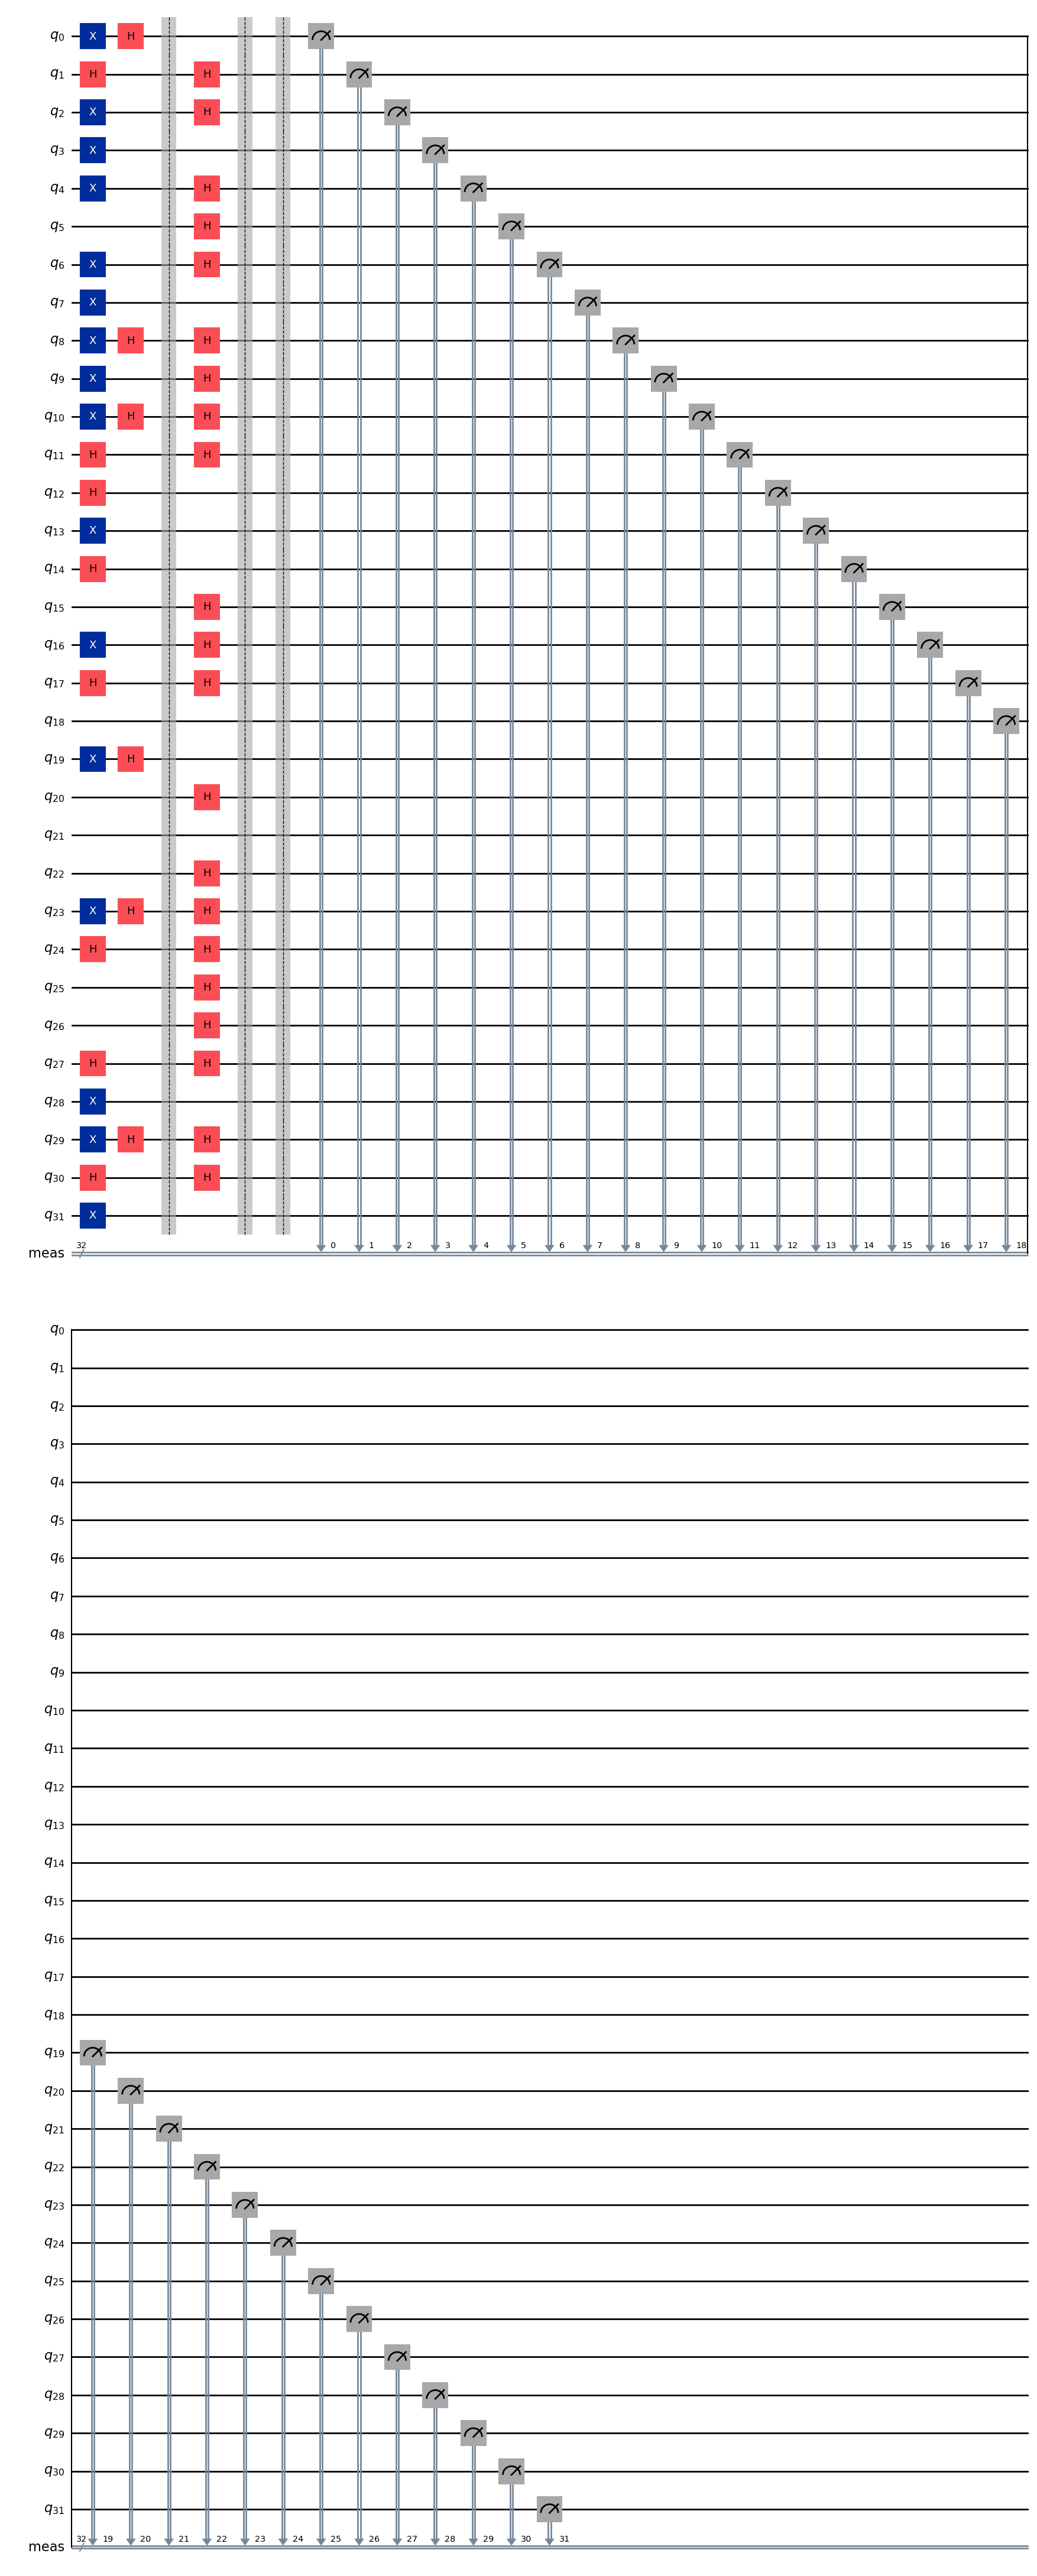

In [5]:
#circuit =
#circuit.draw('mpl')

# Build and visualize the circuit
circuit = bb84_circuit(alice_state, alice_basis, bob_basis)
circuit.draw('mpl')

## Step 3: Creating the key

Once Alice has sent the states through the quantum channel, she sends the bases used to Bob through an **authenticated** classical channel (why?).

Alice and Bob only keep the bits in the strings where the bases match. For example, in the example above only if Alice's encoding basis is 0 and Bob's measuring basis is 0 or its 1 and 1 the bits are kept

The probability that their bases match is $\frac{1}{2}$ as the probability that Alice chooses computational basis is $\frac{1}{2}$ and probability that Bob chooses computational basis is $\frac{1}{2}$ so the probability that both choose computational basis is 1/4 or the probability that both choose hadamard basis is ($\frac{1}{2}$*$\frac{1}{2}$) so in total the probability that both their bases match is $\frac{1}{2}$

Here are all the possibilities for the BB84 protocol

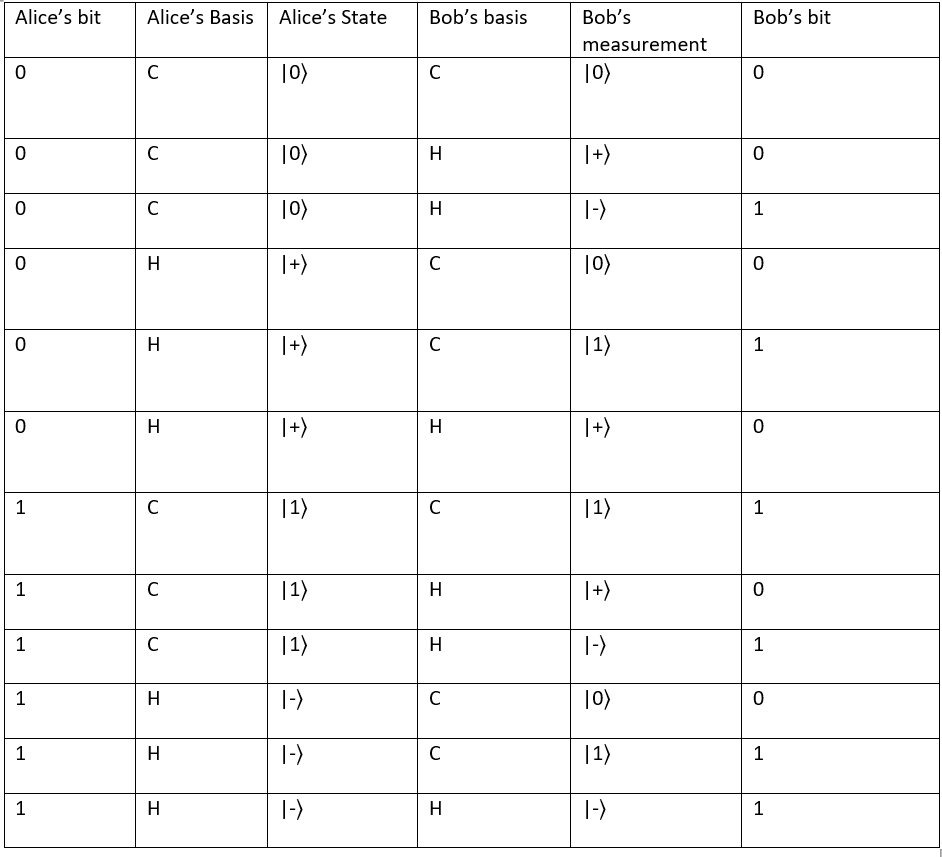

### Step 4: Executing the circuit

In [6]:
# Build the circuit
# Insert your code
circuit = bb84_circuit(alice_state, alice_basis, bob_basis)

#This will print results prettier
from prettytable import PrettyTable
matches = ['✓' if alice_basis[i] == bob_basis[i] else '✘'
           for i in range(num_qubits)]
recovered = [str(alice_state[i]) if alice_basis[i] == bob_basis[i] else '-'
             for i in range(num_qubits)]
table = PrettyTable()
table.field_names = ["i", "Alice bits", "Alice basis", "Bob basis", "Match", "Common key"]

for i in range(num_qubits):
    table.add_row([
        i,
        alice_state[i],
        alice_basis[i],
        bob_basis[i],
        matches[i],
        recovered[i]
    ])
print(table)

# Execute the circuit with 1 shot using AerSimulator
# Insert your code
simulator = AerSimulator()
result = simulator.run(circuit, shots=1).result()
counts = result.get_counts()

# Result comes as {'010101...': 1}; extract the measured string
# Remember that you have to reverse the string due to qiskit's bit ordering
# Insert your code
raw_measured_string = list(counts.keys())[0]
measured_string = raw_measured_string[::-1]

# Extract the common key
encryption_key = ''
# Insert your code
for i in range(num_qubits):
    if alice_basis[i] == bob_basis[i]:
        encryption_key += measured_string[i]

print(f"\nCommon Key:   {encryption_key}")


+----+------------+-------------+-----------+-------+------------+
| i  | Alice bits | Alice basis | Bob basis | Match | Common key |
+----+------------+-------------+-----------+-------+------------+
| 0  |     1      |      1      |     0     |   ✘   |     -      |
| 1  |     0      |      1      |     1     |   ✓   |     0      |
| 2  |     1      |      0      |     1     |   ✘   |     -      |
| 3  |     1      |      0      |     0     |   ✓   |     1      |
| 4  |     1      |      0      |     1     |   ✘   |     -      |
| 5  |     0      |      0      |     1     |   ✘   |     -      |
| 6  |     1      |      0      |     1     |   ✘   |     -      |
| 7  |     1      |      0      |     0     |   ✓   |     1      |
| 8  |     1      |      1      |     1     |   ✓   |     1      |
| 9  |     1      |      0      |     1     |   ✘   |     -      |
| 10 |     1      |      1      |     1     |   ✓   |     1      |
| 11 |     0      |      1      |     1     |   ✓   |     0   

In [7]:
# This is to verify your solution: It ensures that whenever Alice and Bob use the same basis, they measure the same bits.
check = []
pos = 0

for i in range(num_qubits):
    if alice_basis[i] == bob_basis[i]:
        check.append(alice_state[i] == int(encryption_key[pos]))
        pos += 1

assert all(check), "Error: common key does not match transmitted bits."

print("Verification: Keys match!")

Verification: Keys match!
